# Across parts

One part tells you whether that part is good. Fifteen tell you whether the
*process* is. This notebook reads every part at once: a table, two charts that fail
for opposite reasons, and four holes that should match and do not. No 3D.

It starts from the cleaned table built step by step in
[`02-inspection-report`](02-inspection-report.ipynb). Setup is in the
[README](../README.md).

## Setup


`%autoreload 2` re-reads [`qifkit.py`](qifkit.py) before every cell, so an edit
to it takes effect without restarting the kernel.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd

import qifkit

pd.set_option('display.width', 140)

In [2]:
MODEL = '000454_D-MV-FH-2'
doc = qifkit.load(MODEL)

# The cleaned, labeled table from 02-inspection-report, in one call.
clean = qifkit.results(doc)
unit = qifkit.linear_unit(doc)

print(f'{MODEL}: {len(clean)} rows, {clean.serial.nunique()} parts, '
      f'{clean.label.nunique()} characteristics')

000454_D-MV-FH-2: 465 rows, 15 parts, 31 characteristics


## All the parts at once

`fraction` is the deviation from nominal divided by the tolerance on the side it
deviated, as in [`02-inspection-report`](02-inspection-report.ipynb). As a percentage,
0 is on nominal, +/-100 is exactly on a limit, and anything beyond is out of
tolerance. The first table shows it for every characteristic on every part.

In [3]:
# Every characteristic against every part. Reading across a row shows whether a
# characteristic is drifting, scattered, or wrong on every part. That is the
# difference between a process that needs watching and one that needs fixing.
band = clean.pivot_table(index='label', columns='serial', values='fraction', aggfunc='first')
band = band.reindex(columns=sorted(band.columns, key=lambda s: int(s.split('#')[1])))
(band * 100).style.format('{:.0f}', na_rep='')

serial,SN#1,SN#2,SN#3,SN#4,SN#5,SN#6,SN#7,SN#8,SN#9,SN#10,SN#11,SN#12,SN#13,SN#14,SN#15
label,,,,,,,,,,,,,,,
Feature Control Frame (146),3,2,2,4,3,2,2,3,3,3,2,3,3,2,2
Feature Control Frame (147),18,23,23,23,18,21,27,19,20,26,22,24,65,22,21
Feature Control Frame (177),5,5,5,4,5,5,5,5,5,5,5,5,5,5,5
Feature Control Frame (180),4,4,5,6,5,4,4,4,4,5,4,5,4,4,5
Feature Control Frame (183),3,3,5,4,6,8,6,5,5,3,5,4,7,5,4
Feature Control Frame (189) #1,58,276,111,320,337,252,214,239,284,223,510,295,438,110,169
Feature Control Frame (189) #2,22,280,250,209,184,218,209,250,239,94,201,194,354,372,274
Feature Control Frame (189) #3,143,676,146,265,180,148,258,265,276,156,279,313,304,481,289
Feature Control Frame (189) #4,166,167,536,211,142,189,185,181,212,201,335,219,107,153,161


The summary reduces each row to a few numbers. `mean_percent_of_band` is the mean
of the row and `spread_percent_of_band` is its largest value minus its smallest,
both in the same percent-of-band units as the table above. `failed` counts the
parts beyond +/-100.

In [4]:
summary = (clean.assign(out_of_tolerance=clean.fraction.abs() > 1)
           .groupby('label')
           .agg(type=('type', 'first'),
                parts=('serial', 'nunique'),
                failed=('out_of_tolerance', 'sum'),
                mean_percent_of_band=('fraction', lambda f: round(f.mean() * 100, 1)),
                spread_percent_of_band=('fraction', lambda f: round((f.max() - f.min()) * 100, 1)))
           .sort_values(['failed', 'spread_percent_of_band'], ascending=False))

print(f'{len(summary)} characteristics over {clean.serial.nunique()} parts')
print(f'{(summary.failed == summary.parts).sum()} fail on every part'
      f'; those are systematic, not scatter')
summary

31 characteristics over 15 parts
6 fail on every part; those are systematic, not scatter


,type,parts,failed,mean_percent_of_band,spread_percent_of_band
label,,,,,
Feature Control Frame (189) #3,Position,15,15,278.7,533.5
Feature Control Frame (189) #4,Position,15,15,211.1,429.3
Feature Control Frame (201),SurfaceProfile,15,15,117.8,64.4
Radial Dimension (190),Diameter,15,15,-390.1,29.2
Radial Dimension (203),Diameter,15,15,-377.0,29.2
Linear Dimension (194),Width,15,15,-137.3,3.7
Feature Control Frame (189) #1,Position,15,14,255.6,452.8
Feature Control Frame (189) #2,Position,15,13,223.3,350.7
Linear Dimension (133) #2,Width,15,1,-88.6,135.3


## Charting it

A table shows that something failed; a chart shows how. The two charts below can
have the same pass/fail count and still fail for opposite reasons:

- **Bias** - the values barely move, but they sit in the wrong place. The process
  is repeatable and aimed wrong: an offset, a fixture, a tool size. Usually the
  cheap one to fix.
- **Scatter** - the values wander across the band and past it. The process cannot
  hold the dimension at all, and re-centering it will not help.

The table gives the same verdict for both; the corrective action is different.

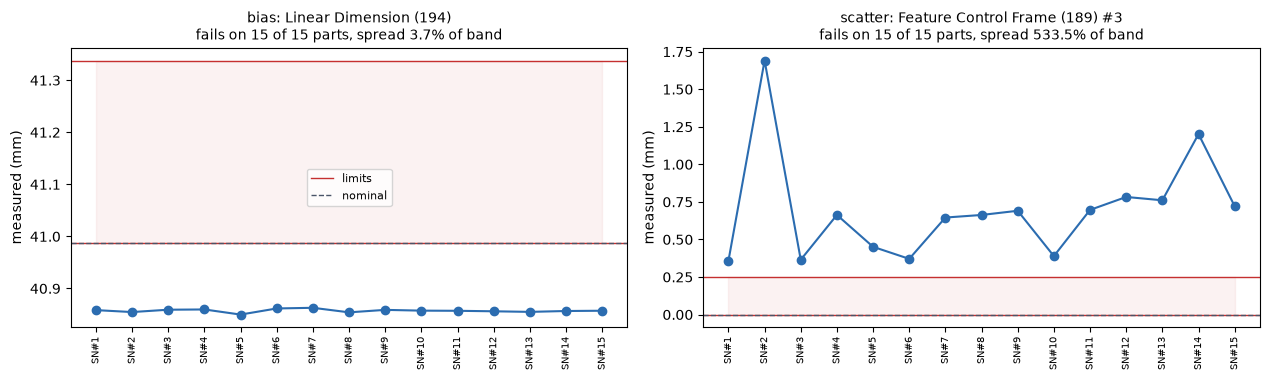

In [5]:
import matplotlib.pyplot as plt


def run_chart(ax, rows, title):
    # A characteristic across parts, in serial order, against its own limits.
    rows = rows.sort_values('serial', key=lambda s: s.map(qifkit.serial_key))
    nominal = 0.0 if pd.isna(rows.nominal.iloc[0]) else rows.nominal.iloc[0]
    upper, lower = nominal + rows.high.iloc[0], nominal + rows.low.iloc[0]

    ax.plot(rows.serial, rows.value, marker='o', color='#2b6cb0', zorder=3)
    # Draw both limits even when one coincides with nominal. On a one-sided band
    # such as +0.2/-0 the closed side is exactly where parts fail, so it must not
    # be the one that goes missing.
    ax.axhline(upper, color='#c53030', lw=1, label='limits')
    ax.axhline(lower, color='#c53030', lw=1)
    ax.axhline(nominal, color='#4a5568', lw=1, ls='--', label='nominal')
    ax.fill_between(rows.serial, lower, upper, color='#c53030', alpha=0.06)
    ax.set_title(title, fontsize=10)
    ax.tick_params(axis='x', rotation=90, labelsize=7)
    ax.set_ylabel(f'measured ({unit})')


# Let the data choose one of each, so this still says something on another model.
failing = summary[summary.failed > 0]

if failing.empty:
    print('Nothing on this model is out of tolerance.')
else:
    # Bias: among what fails on every part (or failing at all, if nothing does),
    # the tightest spread (repeatable, and in the wrong place).
    always = failing[failing.failed == failing.parts]
    bias = (always if len(always) else failing).spread_percent_of_band.idxmin()

    # Scatter: the widest spread among everything else that fails.
    others = failing.drop(index=bias)
    picks = [('bias', bias)] + ([('scatter', others.spread_percent_of_band.idxmax())] if len(others) else [])

    fig, axes = plt.subplots(1, len(picks), figsize=(6.4 * len(picks), 3.9), squeeze=False)
    for ax, (what, label) in zip(axes.flat, picks):
        row = summary.loc[label]
        run_chart(ax, clean[clean.label == label],
                 f'{what}: {label}\nfails on {row.failed} of {row.parts} parts, '
                 f'spread {row.spread_percent_of_band:g}% of band')
    axes.flat[0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()

### Four holes under one callout

One Ø8.73 callout applies to four holes: same nominal, same tolerance, and
probably cut in the same operation. The file does not record how they were made,
but four identical holes on one part usually are. If so, they should come out close
to identical. The charts show whether they do.

Each chart is one hole across the 15 parts. The table summarizes each hole:

| column | meaning |
|---|---|
| **mean** | average measured diameter |
| **std dev** | standard deviation: how much it varies from part to part |
| **min**, **max** | smallest and largest diameter measured |
| **spread** | max − min |

Look at **std dev**. Hole #2 varies about four times less than hole #3, with the
same requirement and probably the same operation. A pass/fail table does not show
this, because all four pass.

The thread picks up again in [`05-probe-points-and-form`](05-probe-points-and-form.ipynb),
which looks at the shape of these holes rather than their size.

Radial Dimension (188): 4 features, nominal 8.73125 mm


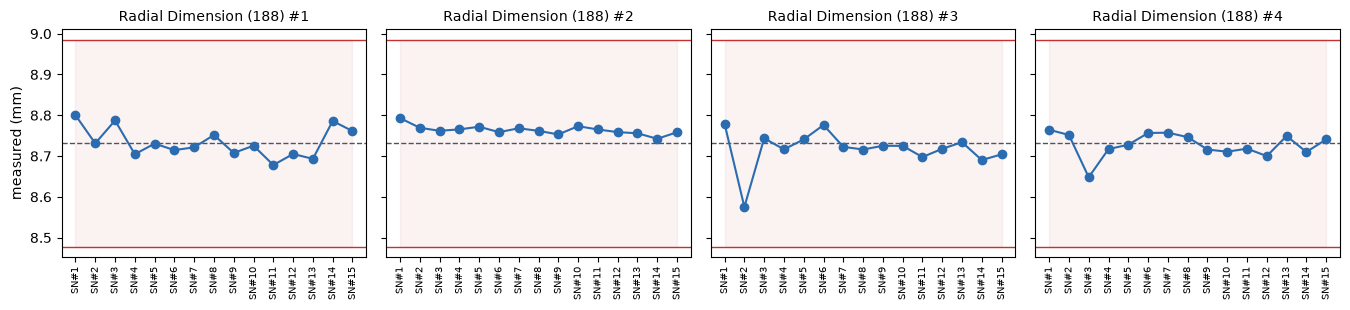

,mean,std dev,min,max,spread
label,,,,,
Radial Dimension (188) #1,8.7332,0.0366,8.6781,8.8002,0.1221
Radial Dimension (188) #2,8.7638,0.0113,8.7423,8.7931,0.0508
Radial Dimension (188) #3,8.7176,0.0466,8.5752,8.7790,0.2038
Radial Dimension (188) #4,8.7276,0.0301,8.6480,8.7645,0.1165


In [6]:
# The largest group of features sharing one callout: same nominal, same
# tolerance, probably cut in the same operation. Chosen from the data rather than
# hardcoded, so this still points somewhere useful on another model.
repeated = clean[clean.type == 'Diameter'].groupby('name').characteristic.nunique()
repeated = repeated[repeated > 1].sort_values(ascending=False)

if repeated.empty:
    print('No diameter callout on this model covers more than one feature.')
else:
    callout = repeated.index[0]
    holes = clean[clean.name == callout]
    names = sorted(holes.label.unique())
    print(f'{callout}: {len(names)} features, nominal {holes.nominal.iloc[0]:g} {unit}')

    # Wrap onto rows rather than one ever-wider strip: the other model's largest
    # callout covers eight holes.
    columns = min(len(names), 4)
    rows = -(-len(names) // columns)
    fig, axes = plt.subplots(rows, columns, figsize=(3.4 * columns, 3.2 * rows),
                             sharey=True, squeeze=False)
    for ax, name in zip(axes.flat, names):
        run_chart(ax, holes[holes.label == name], name)
        ax.set_ylabel('')
    for ax in axes.flat[len(names):]:
        ax.set_visible(False)
    for row in axes:
        row[0].set_ylabel(f'measured ({unit})')
    plt.tight_layout()
    plt.show()

    spread = (holes.groupby('label').value.agg(['mean', 'std', 'min', 'max'])
              .assign(spread=lambda d: d['max'] - d['min'])
              .rename(columns={'std': 'std dev'}).round(4))
    display(spread)